In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## AR(1) simulation

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


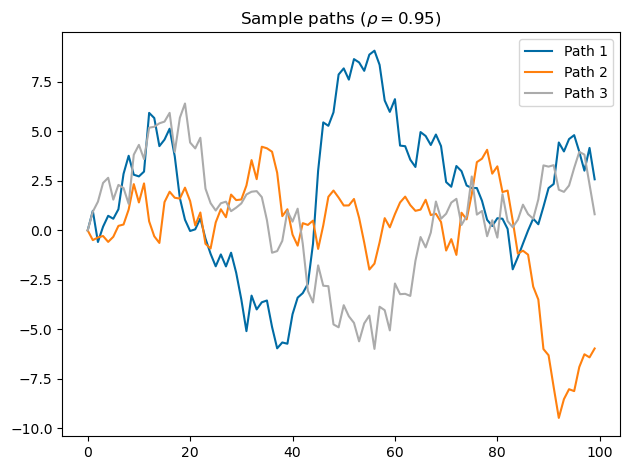

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


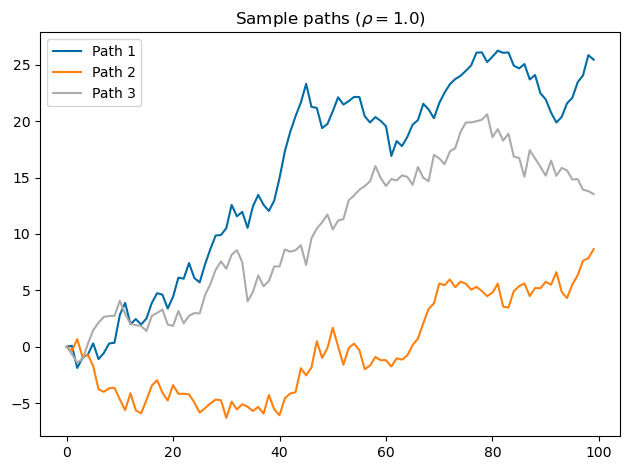

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


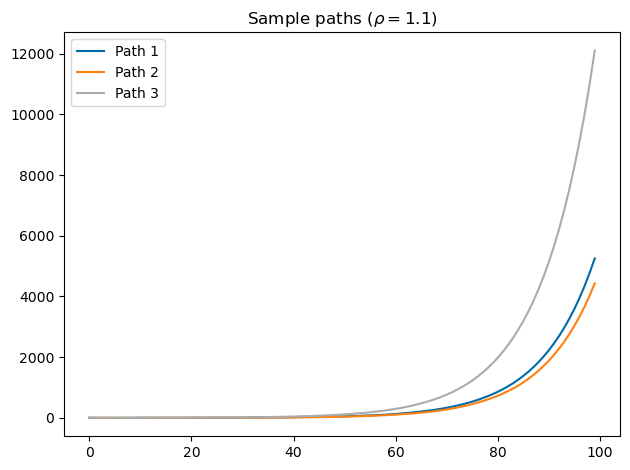

In [2]:
# Parameters
rhos = [0.95, 1.0, 1.1]
T = 100
n_paths = 3
rng = np.random.default_rng(seed=31150)

# Simulate
for rho in rhos:
    y = np.zeros((T, n_paths))
    u = rng.standard_normal((T, n_paths))
    for t in range(1, T):
        y[t] = rho * y[t - 1] + u[t]

    # Plot
    fig, ax = plt.subplots()
    for j in range(n_paths):
        ax.plot(y[:, j], label=f'Path {j + 1}')
    ax.set_title(f'Sample paths ($\\rho = {rho}$)')
    ax.legend()
    plt.tight_layout()
    fig.savefig(f'output/ar_sim_{100*rho:.0f}.eps')
    plt.show()

## AR estimation

In [3]:
# Load data
df = pd.read_csv('data/CPIAUCSL.csv', index_col='observation_date', parse_dates=True)
df = df.interpolate() # interpolate missing value in Oct 2025
cpi = df['CPIAUCSL'].values
y = 100*np.diff(np.log(cpi)) # monthly inflation rate

# AR order
p = 3

# Build regressor matrix: columns are lags of y
X = np.column_stack([y[p-j:-j] for j in range(1, p + 1)])
X = sm.add_constant(X)
Y = y[p:]

# OLS estimation
res = sm.OLS(Y, X).fit(cov_type='HC1')
xnames = ['const'] + [f'lag{j}' for j in range(1, p + 1)]
print(res.summary(xname=xnames, slim=True))
print(f'\nResidual std dev: {np.sqrt(res.mse_resid):.4f}')

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.367
Model:                            OLS   Adj. R-squared:                  0.365
No. Observations:                 946   F-statistic:                     69.29
Covariance Type:                  HC1   Prob (F-statistic):           1.71e-40
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0888      0.015      5.933      0.000       0.059       0.118
lag1           0.5050      0.055      9.192      0.000       0.397       0.613
lag2           0.0250      0.053      0.476      0.634      -0.078       0.128
lag3           0.1584      0.046      3.428      0.001       0.068       0.249

Notes:
[1] Standard Errors are heteroscedasticity robust (HC1)

Residual std dev: 0.2677


## Lag order selection

In [4]:
p_max = 24 # max lag order
p_grid = np.arange(1, p_max + 1)
Y = y[p_max:]
T_eff = len(Y)
aic = np.zeros(p_max)
bic = np.zeros(p_max)

for i, p in enumerate(p_grid):
    # Build regressor matrix (enforce same sample for all p)
    X = np.column_stack([y[p_max-j:-j] for j in range(1, p + 1)])
    X = sm.add_constant(X)
    # OLS estimation
    res = sm.OLS(Y, X).fit()
    sigma2 = np.var(res.resid)
    # Information criteria
    aic[i] = np.log(sigma2) + 2 * p / T_eff
    bic[i] = np.log(sigma2) + np.log(T_eff) * p / T_eff

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


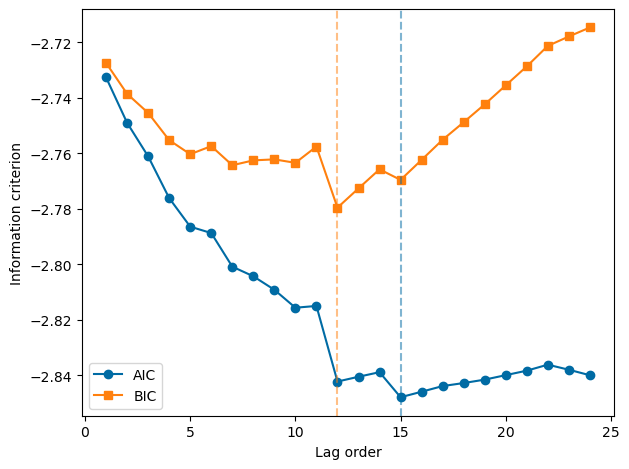

In [5]:
fig, ax = plt.subplots()
ax.plot(p_grid, aic, marker='o', label='AIC')
ax.plot(p_grid, bic, marker='s', label='BIC')
ax.axvline(p_grid[np.argmin(aic)], color='C0', linestyle='--', alpha=0.5)
ax.axvline(p_grid[np.argmin(bic)], color='C1', linestyle='--', alpha=0.5)
ax.set_xlabel('Lag order')
ax.set_ylabel('Information criterion')
ax.legend(loc='lower left')
plt.tight_layout()
fig.savefig('output/ic.eps')
plt.show()

## Monte Carlo simulation: AR(1) estimation

Experiment with changing $T$.

In [ ]:
# Parameters
rho = 0.9
T = 100
n_sim = 5000
rng = np.random.default_rng(seed=31150)

# Monte Carlo loop
rho_hat = np.zeros(n_sim)
for i in range(n_sim):
    # Simulate AR(1)
    u = rng.standard_normal(T)
    y = np.zeros(T)
    for t in range(1, T):
        y[t] = rho * y[t - 1] + u[t]
    # OLS estimation
    X = sm.add_constant(y[:-1])
    Y = y[1:]
    res = sm.OLS(Y, X).fit()
    rho_hat[i] = res.params[1]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


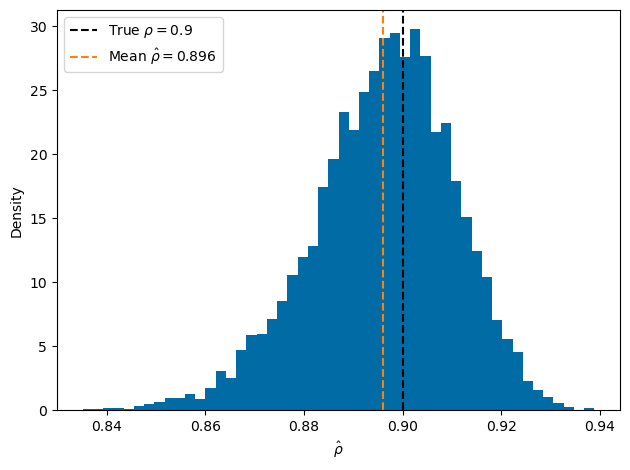

In [7]:
fig, ax = plt.subplots()
ax.hist(rho_hat, bins=50, density=True)
ax.axvline(rho, color='black', linestyle='--', label=f'True $\\rho = {rho}$')
ax.axvline(rho_hat.mean(), color='C1', linestyle='--', label=f'Mean $\\hat\\rho = {rho_hat.mean():.3f}$')
ax.set_xlabel('$\\hat\\rho$')
ax.set_ylabel('Density')
ax.legend(loc='upper left')
plt.tight_layout()
fig.savefig(f'output/mc_ar1_T{T}.eps')
plt.show()